In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results/station1"

# gemeinsames Format der drei Teaser-Grafiken
TEASER_FIGSIZE = (4, 3)
TEASER_YLIM = (0.50, 0.75)
plt.rcParams["font.size"] = 11


def load_runs(folder):
    """Lädt alle ViT-LoRA-Ergebnisse eines Ordners mit Rang und Targets aus dem Namen."""
    # ohne die _history.json-Dateien
    paths = [p for p in folder.glob("vit_lora_r*.json") if not p.stem.endswith("_history")]
    runs = pd.DataFrame([json.loads(p.read_text()) for p in paths])
    # z. B. vit_lora_r8_qkv-proj -> 8, "qkv-proj"
    parts = runs["name"].str.extract(r"_r(\d+)_(.+)$")
    runs["rank"] = parts[0].astype(int)
    runs["targets"] = parts[1]
    return runs.sort_values(["targets", "rank"])


# Sweep über Ränge und Targets mit lr=1e-3
df = load_runs(RESULTS)
# qkv-proj mit lr=2.5e-4
lr_check = load_runs(RESULTS / "lr_check")
df[["name", "targets", "rank", "test_acc", "trainable"]]

,name,targets,rank,test_acc,trainable
8,vit_lora_r4_fc1-fc2,fc1-fc2,4,0.713652,673933
12,vit_lora_r8_fc1-fc2,fc1-fc2,8,0.712594,1042573
0,vit_lora_r16_fc1-fc2,fc1-fc2,16,0.697280,1779853
4,vit_lora_r32_fc1-fc2,fc1-fc2,32,0.684786,3254413
11,vit_lora_r4_qkv,qkv,4,0.706751,452749
15,vit_lora_r8_qkv,qkv,8,0.711738,600205
3,vit_lora_r16_qkv,qkv,16,0.708363,895117
7,vit_lora_r32_qkv,qkv,32,0.704484,1484941
10,vit_lora_r4_qkv-proj,qkv-proj,4,0.710025,532621
14,vit_lora_r8_qkv-proj,qkv-proj,8,0.714610,759949


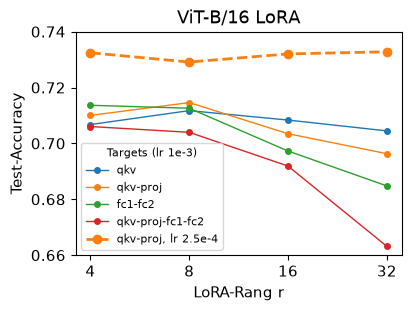

In [18]:
fig, ax = plt.subplots(figsize=TEASER_FIGSIZE, layout="constrained")

# eine Linie pro Target-Konfiguration bei lr=1e-3, sortiert nach Anzahl trainierbarer Parameter
order = df.groupby("targets")["trainable"].min().sort_values().index
colors = {}
for targets in order:
    runs = df[df["targets"] == targets]
    (line,) = ax.plot(runs["rank"], runs["test_acc"], marker="o", markersize=4, linewidth=1, label=targets)
    colors[targets] = line.get_color()

# qkv-proj mit lr=2.5e-4, gleiche Farbe wie qkv-proj bei lr=1e-3
ax.plot(lr_check["rank"], lr_check["test_acc"], marker="o", linestyle="--", linewidth=2,
        color=colors["qkv-proj"], label="qkv-proj, lr 2.5e-4")

ranks = sorted(df["rank"].unique())
ax.set_xscale("log", base=2)  # ränge verdoppeln sich
ax.set_xticks(ranks, labels=ranks)
ax.minorticks_off()
ax.set_ylim(0.66, 0.74)
ax.set_xlabel("LoRA-Rang r")
ax.set_ylabel("Test-Accuracy")
ax.set_title("ViT-B/16 LoRA")
ax.legend(title="Targets (lr 1e-3)", loc="lower left", fontsize=8, title_fontsize=8)
fig.savefig(ROOT / "notebooks/results/station1/vit_lora_rank_vs_acc.pdf")


,name,lr,test_acc,best_val_acc,trainable
2,cnn_lr3e-05,0.00003,0.587154,0.602020,24321485
1,cnn_lr0.0001,0.00010,0.634962,0.665657,24321485
0,cnn_lr0.0003,0.00030,0.627305,0.633838,24321485
3,cnn_lr0.001,0.00100,0.542569,0.551010,24321485


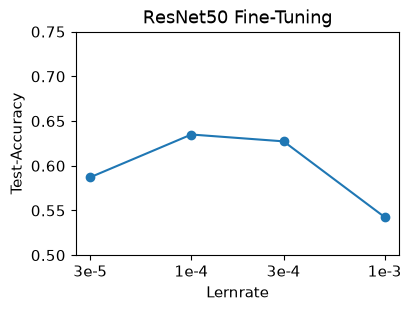

In [ ]:
# ResNet50 (komplettes Fine-Tuning) mit verschiedenen Lernraten
paths = [p for p in RESULTS.glob("cnn_lr*.json") if not p.stem.endswith("_history")]
cnn = pd.DataFrame([json.loads(p.read_text()) for p in paths])
cnn["lr"] = cnn["name"].str.removeprefix("cnn_lr").astype(float)  # z. B. cnn_lr0.0001 -> 1e-4
cnn = cnn.sort_values("lr")

fig, ax = plt.subplots(figsize=TEASER_FIGSIZE, layout="constrained")
ax.plot(cnn["lr"], cnn["test_acc"], marker="o")
ax.set_xscale("log")
ax.set_xticks(cnn["lr"], labels=[f"{lr:.0e}".replace("e-0", "e-") for lr in cnn["lr"]])
ax.minorticks_off()
ax.set_ylim(TEASER_YLIM)
ax.set_xlabel("Lernrate")
ax.set_ylabel("Test-Accuracy")
ax.set_title("ResNet50 Fine-Tuning")
fig.savefig(ROOT / "notebooks/results/station1/cnn_lr_vs_acc.pdf")
cnn[["name", "lr", "test_acc", "best_val_acc", "trainable"]]

,name,lr,test_acc,best_val_acc,trainable
3,vit_linprob_lr3e-05,0.00003,0.637884,0.642424,305293
0,vit_linprob_lr0.0001,0.00010,0.716322,0.736869,305293
1,vit_linprob_lr0.0003,0.00030,0.733804,0.755556,305293
2,vit_linprob_lr0.001,0.00100,0.726650,0.746970,305293


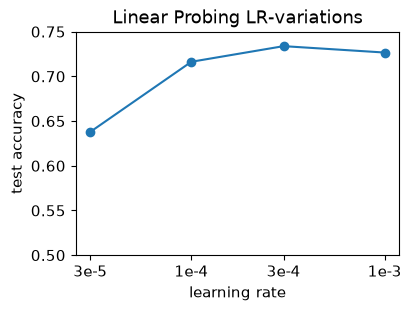

In [3]:
# linear probing mit verschiedenen Lernraten
LINPROBRESULTS = RESULTS / "linear_probe"
paths = [p for p in LINPROBRESULTS.glob("vit_linprob_lr*.json") if not p.stem.endswith("_history")]
linprob = pd.DataFrame([json.loads(p.read_text()) for p in paths])
linprob["lr"] = linprob["name"].str.removeprefix("vit_linprob_lr").astype(float)  # z. B. vit_linprob_lr0.0001 -> 1e-4
linprob = linprob.sort_values("lr")

fig, ax = plt.subplots(figsize=TEASER_FIGSIZE, layout="constrained")
ax.plot(linprob["lr"], linprob["test_acc"], marker="o")
ax.set_xscale("log")
ax.set_xticks(linprob["lr"], labels=[f"{lr:.0e}".replace("e-0", "e-") for lr in linprob["lr"]])
ax.minorticks_off()
ax.set_ylim(TEASER_YLIM)
ax.set_xlabel("learning rate")
ax.set_ylabel("test accuracy")
ax.set_title("Linear Probing LR-variations")
fig.savefig(ROOT / "notebooks/results/station1/linearprobe_lr_vs_acc.pdf")
linprob[["name", "lr", "test_acc", "best_val_acc", "trainable"]]